# Cемантическая сегментация, детекция

## Вступление
Продолжаем работать с изображениями! Сегодня разбираем целых две новые задачи: сегментацию и детекцию.

### План семинара
1. Изучаем сегментацию при помощи U-Net на датасете Carvana
2. Изучаем метрики детекции
3. Детектируем объекты на изображениях при помощи YOLO

## 1. Изучаем сегментацию при помощи U-Net на датасете Carvana

### Скачиваем данные, ставим пакеты

In [ ]:
!wget https://www.dropbox.com/s/tc1qo73rrm3gt3m/CARVANA.zip
!wget https://www.dropbox.com/s/k886cusbuc1afnq/imagenet-mini.zip
!wget https://gist.githubusercontent.com/yrevar/942d3a0ac09ec9e5eb3a/raw/238f720ff059c1f82f368259d1ca4ffa5dd8f9f5/imagenet1000_clsidx_to_labels.txt  # классы имаджнета

!unzip -q CARVANA.zip -d CARVANA
!unzip -q imagenet-mini.zip

!rm -rf ./train/.DS_Store
!rm -rf ./train_masks/.DS_Store
!rm -rf CARVANA.zip
!rm -rf imagenet-mini.zip

!pip install colour -q
!pip install pytorch-lightning -q
!pip install wandb
!pip install ultralytics roboflow

--2026-10-10 10:01:19--  https://www.dropbox.com/s/tc1qo73rrm3gt3m/CARVANA.zip
Resolving www.dropbox.com (www.dropbox.com)... 162.125.1.18, 2620:100:6016:18::a27d:112
Connecting to www.dropbox.com (www.dropbox.com)|162.125.1.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://www.dropbox.com/scl/fi/30c6e8n7m10hbpd2uhv76/CARVANA.zip?rlkey=1wcqbfpj1l5lpz1uq2a7jqcfh [following]
--2026-10-10 10:01:19--  https://www.dropbox.com/scl/fi/30c6e8n7m10hbpd2uhv76/CARVANA.zip?rlkey=1wcqbfpj1l5lpz1uq2a7jqcfh
Reusing existing connection to www.dropbox.com:443.
HTTP request sent, awaiting response... 302 Found
Location: https://ucbd57e96c875c39c039b1a17ddc.dl.dropboxusercontent.com/cd/0/inline/DJvJG46y4NmXnFd2mS79aLHCC0Xx5zu-Cqw_A6yVLOrK5GW3QUx5-59x-xdBzmcO1i_TNRSzxdY0mUtZWvItXetwPcoofEu8H14QMA0DMe8ouCFhTpLWPHe5VkHcl06Y4A49A6rPHV-dVH5rccuYuRwY/file# [following]
--2026-10-10 10:01:20--  https://ucbd57e96c875c39c039b1a17ddc.dl.dropboxusercontent.com/cd/0/inline/DJvJ

In [ ]:
import glob
import math
import os
import warnings
from typing import Dict, List, Tuple

import matplotlib.pyplot as plt
import numpy as np
import pytorch_lightning as pl
import torch
import wandb
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader
from torchvision import transforms

warnings.filterwarnings("ignore")

### Организуем данные в класс

In [ ]:
import albumentations as A
import albumentations.pytorch


class SegmentationDataset(torch.utils.data.Dataset):
    def __init__(self, image_path, mask_path, transforms):
        self.images = glob.glob(os.path.join(image_path, "*.jpg"))
        self.image_path = image_path
        self.mask_path = mask_path
        self.transforms = transforms

    def __getitem__(self, idx):
        img = np.array(Image.open(self.images[idx]).convert("RGB"))
        mask = np.array(
            Image.open(
                os.path.join(
                    self.mask_path,
                    os.path.basename(self.images[idx]).replace(".jpg", "_mask.gif"),
                )
            )
        )
        mask[mask == 255.0] = 1.0
        augmentations = self.transforms(image=img, mask=mask)
        image = augmentations["image"]
        mask = augmentations["mask"]
        mask = torch.unsqueeze(mask, 0)
        mask = mask.type(torch.float32)
        return image, mask

    def __len__(self):
        return len(self.images)

In [ ]:
data = SegmentationDataset(
    image_path="CARVANA/train",
    mask_path="CARVANA/train_masks",
    transforms=A.Compose(
        [A.Resize(height=256, width=256), A.pytorch.transforms.ToTensorV2()]
    ),
)

train_size = 0.9
train_len = math.floor(len(data) * train_size)
val_len = len(data) - train_len
train_dataset, val_dataset = torch.utils.data.random_split(data, [train_len, val_len])

train_loader = torch.utils.data.DataLoader(
    dataset=train_dataset, batch_size=8, shuffle=True, pin_memory=True, num_workers=3
)

val_loader = torch.utils.data.DataLoader(
    dataset=val_dataset, batch_size=8, shuffle=True, pin_memory=True, num_workers=3
)

### Посмотрим на примеры данных

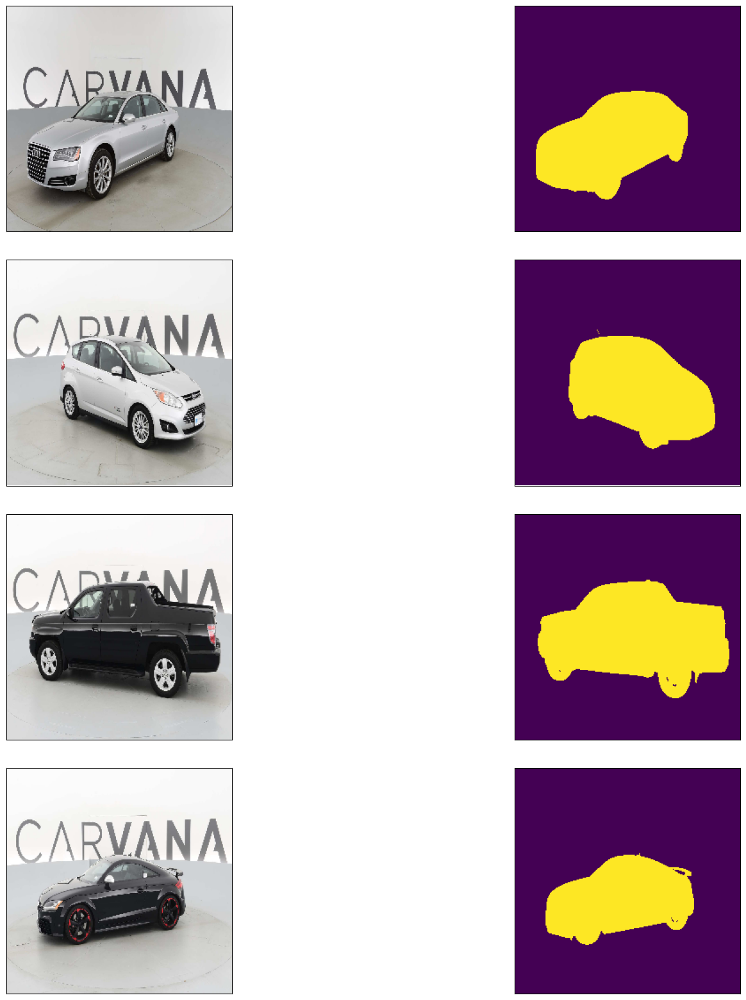

In [ ]:
def im_show(img_list: List[Tuple[str, str]]) -> None:
    """
    Plots images with correspinding segmentation mask

    :param img_list: list of paths to images
    """
    to_PIL = transforms.ToPILImage()
    if len(img_list) > 9:
        raise Exception("len(img_list) must be smaller than 10")

    fig, axes = plt.subplots(len(img_list), 2, figsize=(16, 16))
    fig.tight_layout()

    for idx, sample in enumerate(img_list):
        a = axes[idx][0].imshow(np.array(to_PIL(sample[0])))
        b = axes[idx][1].imshow(np.array(to_PIL(sample[1])))
        for ax in axes[idx]:
            ax.get_xaxis().set_visible(False)
            ax.get_yaxis().set_visible(False)

    plt.show()


img_list = []
for i in range(4):
    img, label = train_dataset[np.random.randint(0, 100)]
    img_list.append((img, label))

im_show(img_list)

### Имплементируем U-Net
#### Архитектура

Дополните недостающий код так, чтобы получилась архитектура [U-net сети](https://arxiv.org/pdf/1505.04597.pdf). Обратите внимание, что при проходе "вниз" количество каналов каждого блока __увеличивается в два раза__. Ситуация с проходом "вверх" противоположна, количество каналов __уменьшается в два раза__. Так же, начинаем мы __не с 64 каналов__, как на схеме ниже, __а с 32 каналов__.

При проходе вниз в нашей реализации предлагается __дойти до 128 каналов__, чтобы сэкономить время обучения, в оригинальной статье было до 1024 (2 блока, вместо 4х). В целом, при отличии количества каналов от указанных выше чисел, модель все равно будет работать, но для удобства проведения семинара лучше всем договориться об одних числах.

<img src="https://lmb.informatik.uni-freiburg.de/people/ronneber/u-net/u-net-architecture.png">

Подсказка: каждый блок по пути "вниз" представляет из себя двойную свертку с батч нормом и активацией (при создании `Relu` слоя не забывайте `inplace=True`).

#### ConvTranspose2d

Также мы познакомимся с вами с операцией **nn.ConvTranspose2d**.

**Зачем она?**
Если операция свертки "сворачивает" (convolution) изображение, то, грубо говоря, эта операция обратная - "разворачивает" (deconvolution). Однако важно понимать, что тут нет вычисления значения, обратного свертке, поэтому не совсем верно называть это deconvolution. В модели U-net мы сворачиваем картинку, а затем будем разворачивать, поэтому без данного способа нам не обойтись.

**Как работает?**
Принимает на вход такие же параметры как Conv2d. Подробнее можно почитать в [объяснении со stackoverflow](https://stackoverflow.com/questions/69782823/understanding-the-pytorch-implementation-of-conv2dtranspose).

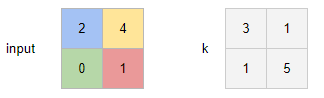

Примеры ниже показывают частные случаи и выходы после данной операции.

**stride=1, padding=0: output is 3x3**
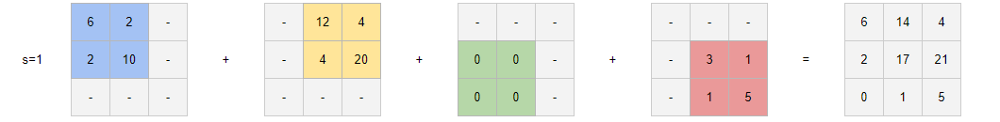

**stride=1, padding=1: output is 1x1**
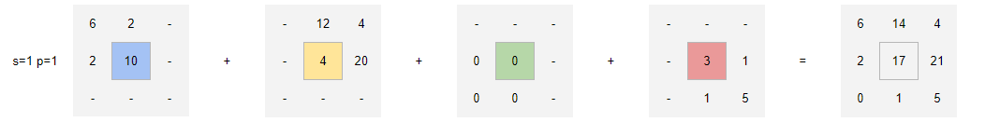

**stride=2, padding=0: output is 4x4**
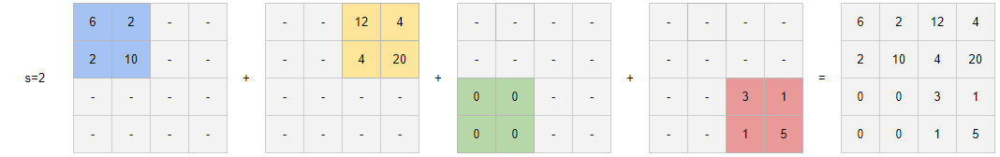

**stride=2, padding=1: output is 2x2**
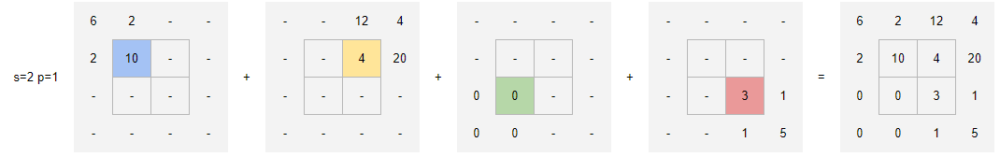

In [ ]:
class ConvBlock(pl.LightningModule):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
        )

    def forward(self, x):
        return self.conv(x)


class UNET(pl.LightningModule):
    def __init__(
        self,
        in_channels: int = 3,
        out_channels: int = 1,
        features: List[int] = [32, 64, 128],
        learning_rate: float = 1.5e-3,
    ):
        super().__init__()
        self.learning_rate = learning_rate
        self.down = nn.ModuleList()
        self.up = nn.ModuleList()
        self.pool = nn.MaxPool2d(2, 2)  # Phase change
        for feature in features:
            self.down.append(ConvBlock(in_channels=in_channels, out_channels=feature))
            in_channels = feature
        for feature in reversed(features):
            self.up.append(
                nn.ConvTranspose2d(
                    in_channels=feature * 2,
                    out_channels=feature,
                    kernel_size=2,
                    stride=2,
                )
            )
            self.up.append(
                ConvBlock(
                    in_channels=feature * 2, out_channels=feature
                )  # x gets concat to 2xchannel
            )
        self.bottleneck = ConvBlock(
            in_channels=features[-1], out_channels=features[-1] * 2
        )
        self.final_conv = nn.Conv2d(
            in_channels=features[0], out_channels=out_channels, kernel_size=1
        )
        self.loss_fn = nn.BCEWithLogitsLoss()
        self.optimizer = torch.optim.AdamW(
            self.parameters(), lr=self.learning_rate, weight_decay=0.3
        )

        self.val_num_correct = 0
        self.val_num_pixels = 0
        self.val_dice_score = 0
        self.num_correct = 0
        self.num_pixels = 0
        self.dice_score = 0

        self.training_step_outputs = []
        self.validation_step_outputs = []

        self.training_step_dice = []
        self.validation_step_dice = []

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        skip_connections = []  # storage for skip connections
        for down in self.down:
            x = down(x)
            skip_connections.append(x)
            x = self.pool(x)
        x = self.bottleneck(x)
        skip_connections = skip_connections[::-1]  # reverse list
        for idx in range(0, len(self.up), 2):
            x = self.up[idx](x)
            skip_connection = skip_connections[idx // 2]
            if x.shape != skip_connection.shape:
                x = transforms.functional.resize(x, size=skip_connection.shape[2:])
            concat_skip = torch.cat(
                (skip_connection, x), dim=1
            )  # Concat along channels dimensions (b, c, h, w)
            x = self.up[idx + 1](concat_skip)
        return self.final_conv(x)

    def configure_optimizers(self):
        return self.optimizer

    def training_step(self, batch: torch.Tensor, batch_idx) -> Dict[str, torch.Tensor]:
        x, y = batch
        pred = self(x.float())
        loss = self.loss_fn(pred, y)
        pred = torch.sigmoid(pred)
        pred = (pred > 0.5).float()
        self.num_correct += (pred == y).sum()
        self.num_pixels += torch.numel(pred)
        self.training_step_dice.append(
            (2 * (pred * y).sum()) / ((pred + y).sum() + 1e-8)
        )
        self.log("train_loss", loss, prog_bar=True)
        self.training_step_outputs.append(loss)
        return {"loss": loss}

    def on_train_epoch_end(self):
        epoch_average = torch.stack(self.training_step_outputs).mean()
        train_acc = float(f"{(self.num_correct/self.num_pixels)*100:.2f}")
        self.log("train_acc", train_acc, prog_bar=True)
        dice_score = torch.stack(self.training_step_dice).mean()
        self.log("train_dice_score", dice_score, prog_bar=True)
        self.num_correct, self.num_pixels, self.dice_score = 0, 0, 0
        self.training_step_outputs.clear()
        self.training_step_dice.clear()

    def validation_step(
        self, batch: torch.Tensor, batch_idx: int
    ) -> Dict[str, torch.Tensor]:
        x, y = batch
        pred = self(x.float())
        loss = self.loss_fn(pred, y)
        pred = torch.sigmoid(pred)
        pred = (pred > 0.5).float()
        self.val_num_correct += (pred == y).sum()
        self.val_num_pixels += torch.numel(pred)
        self.validation_step_dice.append(
            (2 * (pred * y).sum()) / ((pred + y).sum() + 1e-8)
        )
        self.log("val_loss", loss, prog_bar=True)
        self.validation_step_outputs.append(loss)
        return {"loss": loss}

    def on_validation_epoch_end(self):
        epoch_average = torch.stack(self.validation_step_outputs).mean()
        val_acc = float(f"{(self.val_num_correct / self.val_num_pixels) * 100:.2f}")
        self.log("val_acc", val_acc, prog_bar=True)
        dice_score = torch.stack(self.validation_step_dice).mean()
        self.log("val_dice_score", dice_score, prog_bar=True)
        self.val_num_correct, self.val_num_pixels, self.val_dice_score = 0, 0, 0
        self.validation_step_outputs.clear()
        self.validation_step_dice.clear()

In [ ]:
pl.utilities.model_summary.summarize(UNET(), -1)

   | Name              | Type              | Params | Mode  | FLOPs
-------------------------------------------------------------------------
0  | down              | ModuleList        | 287 K  | train | 0    
1  | down.0            | ConvBlock         | 10.2 K | train | 0    
2  | down.0.conv       | Sequential        | 10.2 K | train | 0    
3  | down.0.conv.0     | Conv2d            | 864    | train | 0    
4  | down.0.conv.1     | BatchNorm2d       | 64     | train | 0    
5  | down.0.conv.2     | ReLU              | 0      | train | 0    
6  | down.0.conv.3     | Conv2d            | 9.2 K  | train | 0    
7  | down.0.conv.4     | BatchNorm2d       | 64     | train | 0    
8  | down.0.conv.5     | ReLU              | 0      | train | 0    
9  | down.1            | ConvBlock         | 55.6 K | train | 0    
10 | down.1.conv       | Sequential        | 55.6 K | train | 0    
11 | down.1.conv.0     | Conv2d            | 18.4 K | train | 0    
12 | down.1.conv.1     | BatchNorm2d      

In [ ]:
torch.cuda.empty_cache()
model = UNET()

trainer = pl.Trainer(max_epochs=2, accelerator="gpu", devices=1)

trainer.fit(model, train_loader, val_loader)

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud uploads and versioning, try installing [litmodels](https://pypi.org/project/litmodels/) to enable LitModelCheckpoint, which syncs automatically with the Lightning model registry.
INFO:pytorch_lightning.accelerators.cuda:LOCAL_RANK: 0 - CUDA_VISIBLE_DEVICES: [0]


┏━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━┳━━━━━━━┳━━━━━━━┓
┃   ┃ Name       ┃ Type              ┃ Params ┃ Mode  ┃ FLOPs ┃
┡━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━╇━━━━━━━╇━━━━━━━┩
│ 0 │ down       │ ModuleList        │  287 K │ train │     0 │
│ 1 │ up         │ ModuleList        │  753 K │ train │     0 │
│ 2 │ pool       │ MaxPool2d         │      0 │ train │     0 │
│ 3 │ bottleneck │ ConvBlock         │  885 K │ train │     0 │
│ 4 │ final_conv │ Conv2d            │     33 │ train │     0 │
│ 5 │ loss_fn    │ BCEWithLogitsLoss │      0 │ train │     0 │
└───┴────────────┴───────────────────┴────────┴───────┴───────┘

Trainable params: 1.9 M                                                                                            
Non-trainable params: 0                                                                                            
Total params: 1.9 M                                                                                                
Total estimated model params size (MB): 7.708                                                                      
Modules in train mode: 64                                                                                          
Modules in eval mode: 0                                                                                            
Total FLOPs: 0

Output()

INFO:pytorch_lightning.utilities.rank_zero:`Trainer.fit` stopped: `max_epochs=2` reached.


### Посмотрим на результаты

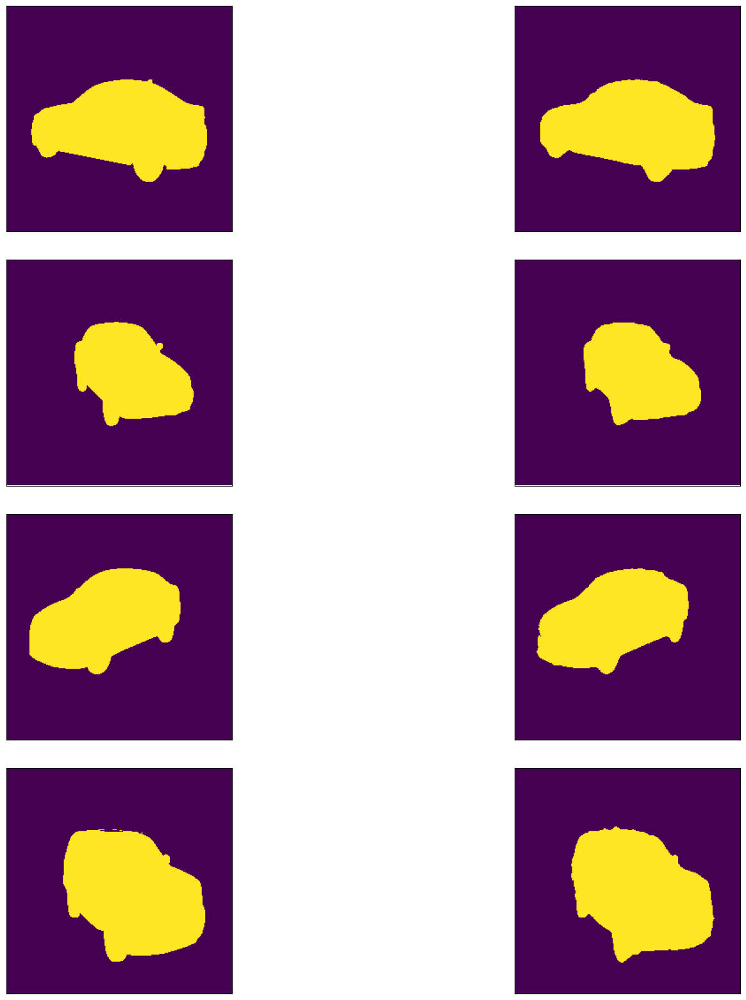

In [ ]:
def mask_to_image(mask: np.ndarray) -> np.ndarray:
    if mask.ndim == 2:
        return np.array((mask * 255).astype(np.uint8))
    elif mask.ndim == 3:
        return np.array(
            (np.argmax(mask, axis=0) * 255 / mask.shape[0]).astype(np.uint8)
        )


def predict_img(
    net: nn.Module, img: torch.Tensor, device: str, out_threshold: float = 0.5
) -> np.ndarray:
    net.eval()
    net.to(device)

    img = img.unsqueeze(0)
    img = img.to(device=device, dtype=torch.float32)

    with torch.no_grad():
        output = net(img)

        probs = torch.sigmoid(output)
        full_mask = probs.cpu().squeeze()

        return (full_mask > out_threshold).numpy()


img_list = []
for i in range(4):
    # img_base, img = train_dataset[np.random.randint(0, 100)]
    img_base, img = val_dataset[np.random.randint(0, 100)]
    mask = predict_img(model, img_base, device="cuda:0")
    result = mask_to_image(mask)
    img_list.append((img, result))
im_show(img_list)

In [ ]:
# освободим память
torch.cuda.empty_cache()

---

## 2. Изучаем метрики детекции

### Intersection over union (IoU)

<img src=https://www.pyimagesearch.com/wp-content/uploads/2016/09/iou_equation.png>


Пример как это выглядит в коде

```
def intersection_over_union(dt_bbox: np.array, gt_bbox: np.array) -> float:
    """
    Intersection over Union between two bboxes
    (x0, y0) - coordinates of the upper left bbox corner
    (x1, y1) - coordinates of the down right bbox corner

    :param dt_bbox: list or numpy array of size (4,) [x0, y0, x1, y1]
    :param gt_bbox: list or numpy array of size (4,) [x0, y0, x1, y1]
    :return : intersection over union
    """
    # upper left corner
    int_x0 = max(dt_bbox[0], gt_bbox[0])
    int_y0 = max(dt_bbox[1], gt_bbox[1])
    # bottom right corner
    int_x1 = min(dt_bbox[2], gt_bbox[2])
    int_y1 = min(dt_bbox[3], gt_bbox[3])

    intersection = max(int_x1 - int_x0, 0) * max(int_y1 - int_y0, 0)
    dt_area = (dt_bbox[2] - dt_bbox[0]) * (dt_bbox[3] - dt_bbox[1])
    gt_area = (gt_bbox[2] - gt_bbox[0]) * (gt_bbox[3] - gt_bbox[1])

    return intersection / (dt_area + gt_area - intersection)
```


### Mean average precision

Сперва вспомним базовые понятия точности и полноты.

<br>
$$ Precision = {TP \over TP + FP} $$
<br>
$$ Recall = {TP \over TP + FN} $$
<br>
<br>TP - True Positive
<br>FP - False Positive
<br>FN - False Negative
<br> <br>

__Precision__ - доля объектов, названных классификатором положительными и при этом действительно являющимися положительными, среди всех объектов, названных классификатором положительными.

__Recall__ - доля объектов, названных классификатором положительными и при этом действительно являющимися положительными, среди всех истинно положительных объектов.

В задаче детекции метки TP, FP, FN (чаще всего) выдаются по следующей логике:

- метка TP выдается в случае, если IoU > 0.5 и класс определен правильно
- метка FP выдается в случае, если IoU <= 0.5 и/или если Bounding Box'ы дублируются
- метка FN выдается, если IoU > 0.5, но неправильно определен класс и/или если бокса нет совсем

#### Чтобы было нагляднее

* зеленый цвет - истинный бокс и класс
* синий - наши предсказания

**True Positive**

У нас два волка, оба определены своим классом и боксы, очевидно, имеют IoU больше 0.5.

<img src="https://github.com/hse-ds/iad-deep-learning/blob/master/2021/seminars/sem06/TruePositiveVolks.jpg?raw=1">

**False Positive**

Несмотря на то, что класс определен правильно и бокс, в целом, выглядит логично на своем месте, IoU слишком мал, поэтому такая детекция получает метку FP.
<img src="https://github.com/hse-ds/iad-deep-learning/blob/master/2021/seminars/sem06/FalsePositiveVolk.jpg?raw=1">

**False Negative**

Потому что, несмотря на хорошее пересечение предсказанного бокса с целевым, класс с высокой уверенностью определен неправильно.

<img src="https://github.com/hse-ds/iad-deep-learning/blob/master/2021/seminars/sem06/FalseNegativeVolk.jpg?raw=1">


### PR-кривая

Далее, для подсчёта mAP нужно построить PR-кривую. Напомним, что это кривая, у которой по оси Y - значение Precision, а по оси X - значение recall. Эти значения считаются при переборе пороговых вероятностей, начиная с которых объект помечается положительным классом.

Для задачи бинарной классификации мы когда-то строили такую кривую, теперь рассмотрим чуть более сложный случай, где у нас три класса: Волк, Лев и Тигр; плюс решается задача детекции, а не классификации.

Внизу представлена таблица с игрушечными данными по предсказаниям модели. Допустим, из 7 объектов в датасете у нас только 3 волка. В данном случае мы называли объект "действительно волком", если он имел правильный класс и IoU не менее 0.5. Получается, имеем задачу вида one vs all, где интересующим нас классом будет являться именно "волк".

|Номер строки| Уверенность в том что волк (истинный класс)    |IoU не менее 0.5?   |  Precision  |  Recall |
|------------|------------------------|----------------------|-------------|---------|
|1           |0.92 (Волк)     |   True    |    1.0     |    0.33 |
|2           |0.83 (Волк)     |   True    |    1.0     |    0.67 |
|3           |0.77 (Волк)     |   False   |    0.67    |    0.67 |
|4           |0.71 (Лев)      |   False   |    0.50    |    ...  |
|5           |0.67 (Тигр)     |   False   |    0.40    |    .... |
|6           |0.54 (Волк)     |   True    |    0.50    |    .... |
|7           |0.47 (Тигр)     |   False   |    0.50    |    1.0  |

<h6>Посчитаем Precision и Recall для порога в 0.9:</h6>
Здесь все легко: взяли порог в 0.9 и называем волками всех, у кого уверенность в классе "Волк" больше 0.9. Один TP, отсутсвуют FP и два FN (2 и 6 строчки).
$$Precision ={  1 \over 1 + 0} = 1.0$$

$$Recall = {1 \over 1 + 2} = 0.33$$

<h6>для порога в 0.8:</h6>
Здесь тоже без дополнительных сложностей: таким порогом во второй строчке у нас нашелся еще один TP, соответственно убавился один FN. Остальное осталось так же.
$$Precision ={  2 \over 2 + 0} = 1.0$$

$$Recall = {2 \over 2 + 1} = 0.67$$

<h6>для порога в 0.75:</h6>  
А вот при пороге в 0.75 в третьей строчке замечаем, что, несмотря на то что истинный класс действительно "Волк" (чем мы и называем данный объект), IoU c истинным боксом меньше 0.5, поэтому присваиваем метку FP.
$$Precision ={  2 \over 2 + 1} = 0.67$$

$$Recall = {2 \over 2 + 1} = 0.67$$

<h6>Задание:</h6> Посчитать недостающие в таблице значения precision и recall и сравнить с изображенной PR кривой.

PR кривая будет выглядеть следующим образом:

<img src="https://github.com/hse-ds/iad-deep-learning/blob/master/2021/seminars/sem06/pr_uno.png?raw=1">

### Монотонная PR-кривая

**Average Precision (AP)** стандартно **определяется как AUC-PR**, то есть как площадь по PR кривой. Из-за того что Precision и Recall находятся в отрезке от 0 до 1, AP также определена на этом отрезке. Чем ближе к 1, тем качественнее модель.

Для удобства вычислений и чуть большей устойчивости к перестановке, вместо того чтобы терпеть возникшую немонотонность, для всех совпадающих значений recall'a берется максимальный справа от текущей точки precision, то есть график изменится следующим образом:

<img src="https://github.com/hse-ds/iad-deep-learning/blob/master/2021/seminars/sem06/pr_dos.png?raw=1">

Технология та же: для вычисления AP считается AUC под красной кривой:

$$AP = 1 * 0.67 + (1 - 0.67) * 0.5 = 0.835.$$

### k-point interpolation

В какой-то момент люди решили, что просто площади — теперь не круто и в популярном соревновании PASCAL VOC2008 для вычисления Average Precision использовалась 11-point interpolation.

По простому: брались 11 значений монотонной PR функции, в точках 0, 0.1, 0.2, ..., 0.9, 1.0 и усреднялись. <br>Для любителей формул:

$$AP = {1 \over11} * \sum P(r), r \in [0.1, 0.2, ..., 0.9, 1.0],$$
$P(r)$ — значение Precision при определенном Recall.

Графически это все выглядит следующим образом:

<img src="https://github.com/hse-ds/iad-deep-learning/blob/master/2021/seminars/sem06/pr_tres.png?raw=1">

Посчитаем АР данным способом:
$$AP = {1 \over {11}} (1 * 7 + 3 * 0.5) = 0.77.$$

#### Подсчёт mAP и другие метрики в задачах детекции

Для более <font color="green">fresh </font> PASCAl VOC соревнований (2011 - 2012) было принято решение считать **Average Precision** как обычную __площадь под монотонной PR кривой__. Этого определения мы и будем придерживаться далее.

Все предыдущие графики, наша первая табличка и значения AP считались для одного класса "Волк". Понятно, что подобные значения можно посчитать для каждого класса в выборке. И каждый раз будет принцип one vs all, где различаются нужный класс и "все остальные".

Метрика __mean Average Precison__ считается как среднее между __AP__ каждого класса, т.е.:

$$mAP = \sum_{c \in C} AP(c),$$
где С — множество классов.

<br>Ниже пример того, как считать среднее :))

*для Average Precision льва и тигра значения взяты случайно

|AP(Волк)| AP(Лев) | AP(Тигр)|mAp    |
|--------|---------|---------|-------|
|0.835   |0.83     | 0.77    | 0.81  |

## 3. Детектируем объекты на изображениях при помощи YOLO

### Семейства моделей детекции

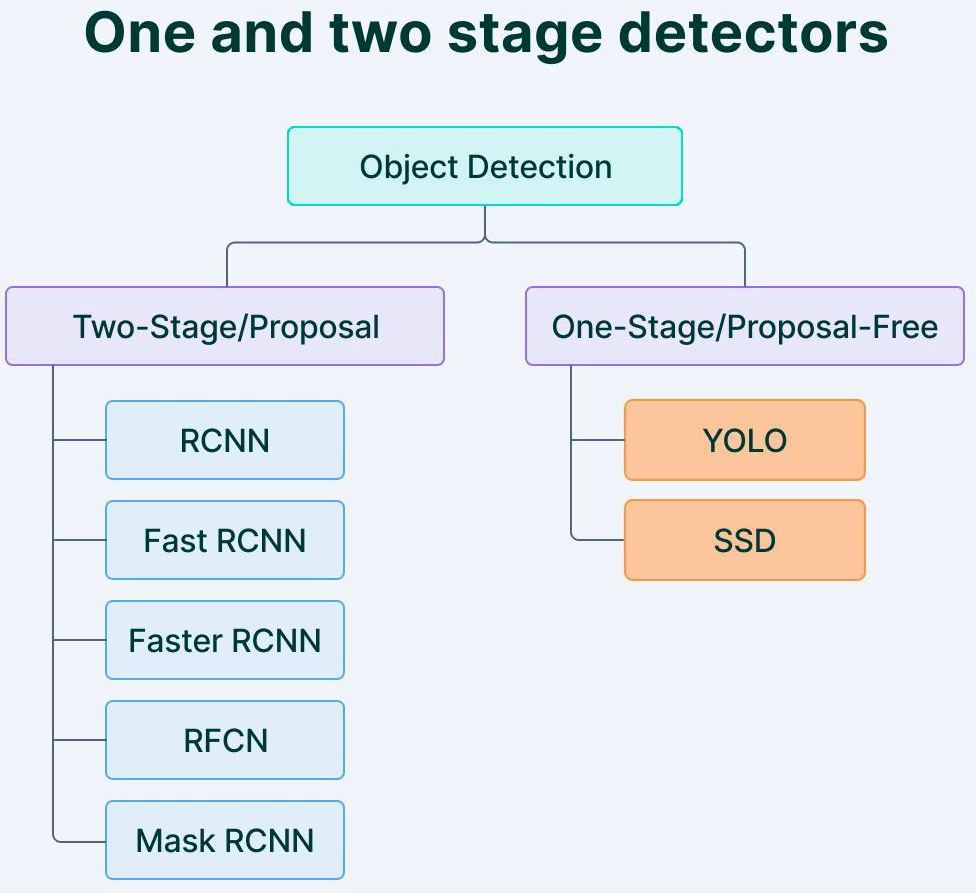

Грубо говоря, можно разделить классический подход к детекции на две основные ветви.


**Коротко про каждый подход:**

1. **RCNN подход**: Предполагает двухэтапный проход модели по изображению, где изначально выделяются зоны способами классического компьютерного зрения, а затем происходит уже знакомая нам классификация объектов в зонах и предсказание с помощью задачи регрессии координат box для объектов.
Одна из последних [статей](https://paperswithcode.com/paper/mask-r-cnn).

2. **YOLO подход**: Одноэтапный детектор удаляет процесс извлечения области интереса и напрямую классифицирует и регрессирует анкерные блоки-кандидаты. YOLO — это архитектура обнаружения объектов, которая называется YOU ONLY LOOK ONCE. Это включает в себя использование одной нейронной сети, обученной от начала до конца, для обработки фотографии и прогнозирования ограничивающих рамок и меток классов для каждой ограничивающей рамки напрямую. Существует несколько версий, которые постоянно совершенствуются, например: YOLOv3, YOLOv4, YOLOv5, [YOLOv7](https://paperswithcode.com/paper/yolov7-trainable-bag-of-freebies-sets-new).

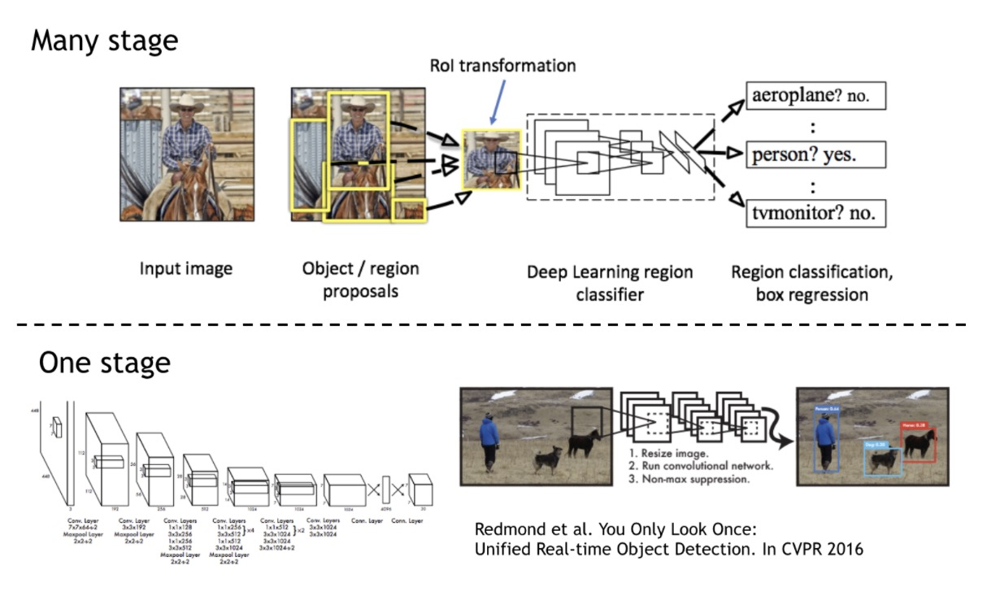

### Data

Существует удобный фреймворк [Roboflow](https://roboflow.com/), благодаря которому можно легко находить, размечать и создавать данные для разных задач, в том числе сегментации и детекции.
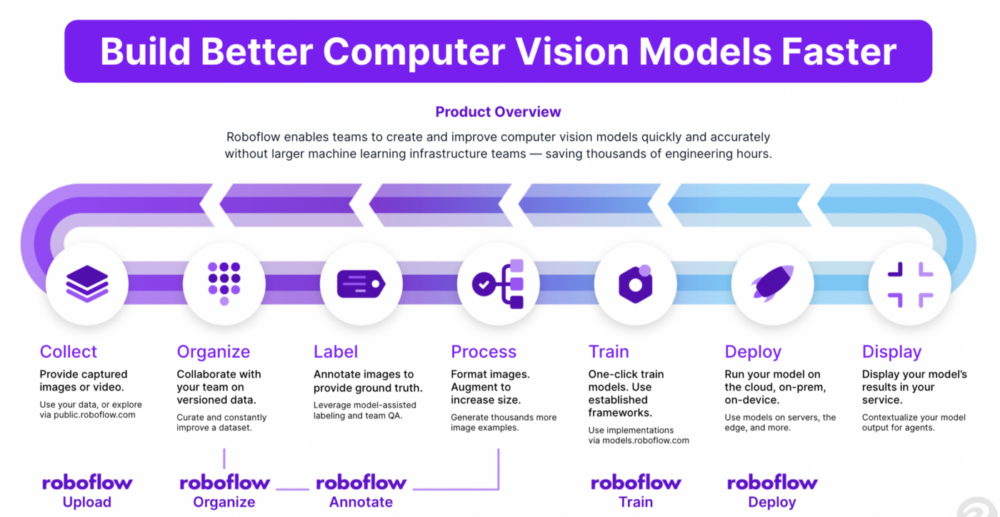

#### Какие проблемы решает Roboflow

**Roboflow** реализован как обычный питновский пакет, что упрощает его использование.

**В детекции** существуют ряд сложностей с данными и моделями, поэтому для всех них требуется специальный формат и поля (для разных данных и моделей)

* Регистрируемся на сайте https://roboflow.com/ (через тот же гугл аккаунт, что и коллаб, самое простое)

**Roboflow решает много проблем, например:**

1. Загрузка изображений и конвертация из одного формата в другой: https://roboflow.com/formats
2. Поиск и разметках данных. После регистрации можно поискать или разметить себе данные для любых задач, а также попробовать уже обученные модели на данные: https://universe.roboflow.com/
3. Удобный просмотр данных, их резделение, аугментации и трансформации; визуализации общей статистики: https://app.roboflow.com/hsedeeplearning/ogo-2/health
4. Как в первом пункте, но уже после создания данных, можно под нужную задачу экспортировать данные: https://app.roboflow.com/hsedeeplearning/ogo-2/1/export

Платно можно даже хостить CV модели и дообучать их на сайте!


#### Создаем кастомные данные с Roboflow

В нашем случае Roboflow проект уже создан, и данные в нём собраны, поэтому мы просто импортируем их. [Смешные данные давайте посмотрим по ссылке](https://app.roboflow.com/hsedeeplearning/ogo-2/browse?queryText=&pageSize=50&startingIndex=0&browseQuery=true). В другой панели в этом проекте — [Versions](https://app.roboflow.com/hsedeeplearning/ogo-2/1) — через кнопку Export выбираем способ экспортирования (в данном случае для yolov8 модели).

In [ ]:
from roboflow import Roboflow

rf = Roboflow(api_key="JwyQYQDzo074YuDcTtJx")
project = rf.workspace("hsedeeplearning").project("ogo-2")

# В данном случае скачиваются все данные, а также создается верный файл конфигурации (в данном случае yaml)
dataset = project.version(1).download("yolov8")

loading Roboflow workspace...
loading Roboflow project...


In [ ]:
dataset.__dict__

{'name': 'ogo-2',
 'version': '1',
 'model_format': 'yolov8',
 'location': '/content/ogo-2-1'}

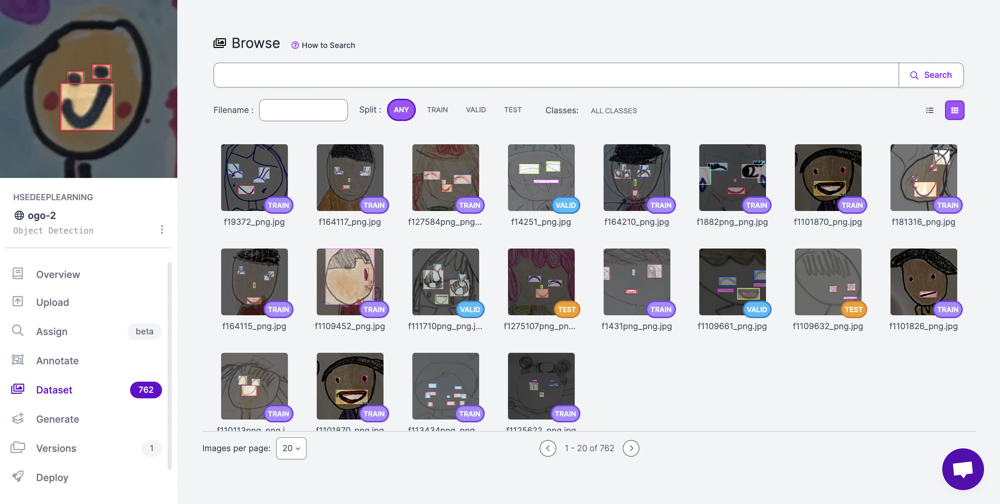

### Обучение модели

Мы не будем полностью реализовывать архитектуру сети, а возьмем сразу готовую реализацию. Реализацию Fast-RCNN можно посмотреть в [ноутбуке с 21 года](https://github.com/hse-ds/iad-deep-learning/blob/master/2021/seminars/sem06/sem_06_solved.ipynb).

In [ ]:
# 15 эпох проходят за ~10 минут
from ultralytics import YOLO

model = YOLO("yolo11n.pt")
_ = model.train(data=f"{dataset.location}/data.yaml", epochs=15)

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/ogo-2-1/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=

Видно, как быстро обучается yolo модель, давайте прогоним на инференс.

In [ ]:
# Run evaluation
_ = model.val(data=f"{dataset.location}/data.yaml")

Ultralytics 8.4.175 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,600,696 parameters, 0 gradients, 6.5 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1317.1±523.0 MB/s, size: 38.9 KB)
val: Scanning /content/ogo-2-1/valid/labels.cache... 152 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 152/152 49.0Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 2.0it/s 5.0s
                   all        152        783      0.861      0.865      0.912      0.731
             arrow-eye          7          9      0.948          1      0.995      0.872
                   bar         23         34      0.808      0.744      0.815       0.58
                  brow         12         20      0.947      0.892       0.97       0.81
                   dot         45         75      0.941      0.987      0.979      0.816
                   ear         34         52 

Predictions



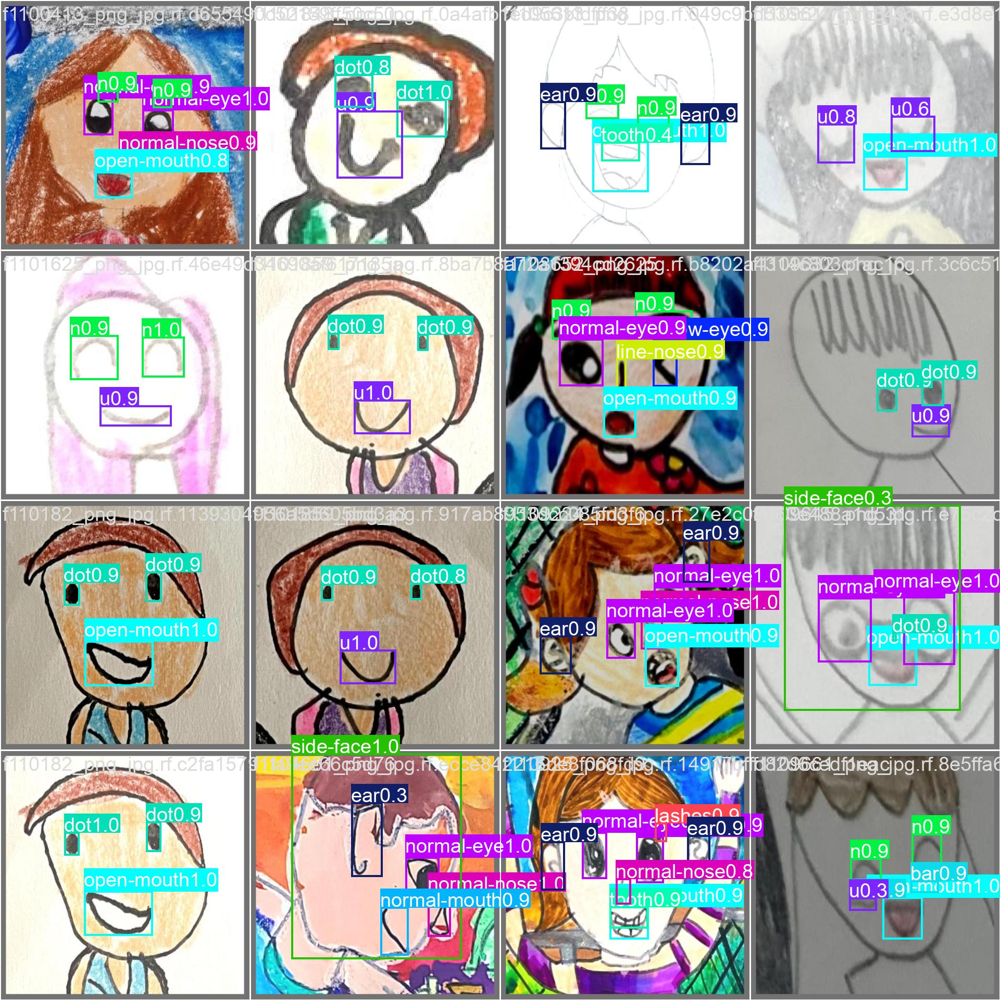





Predictions



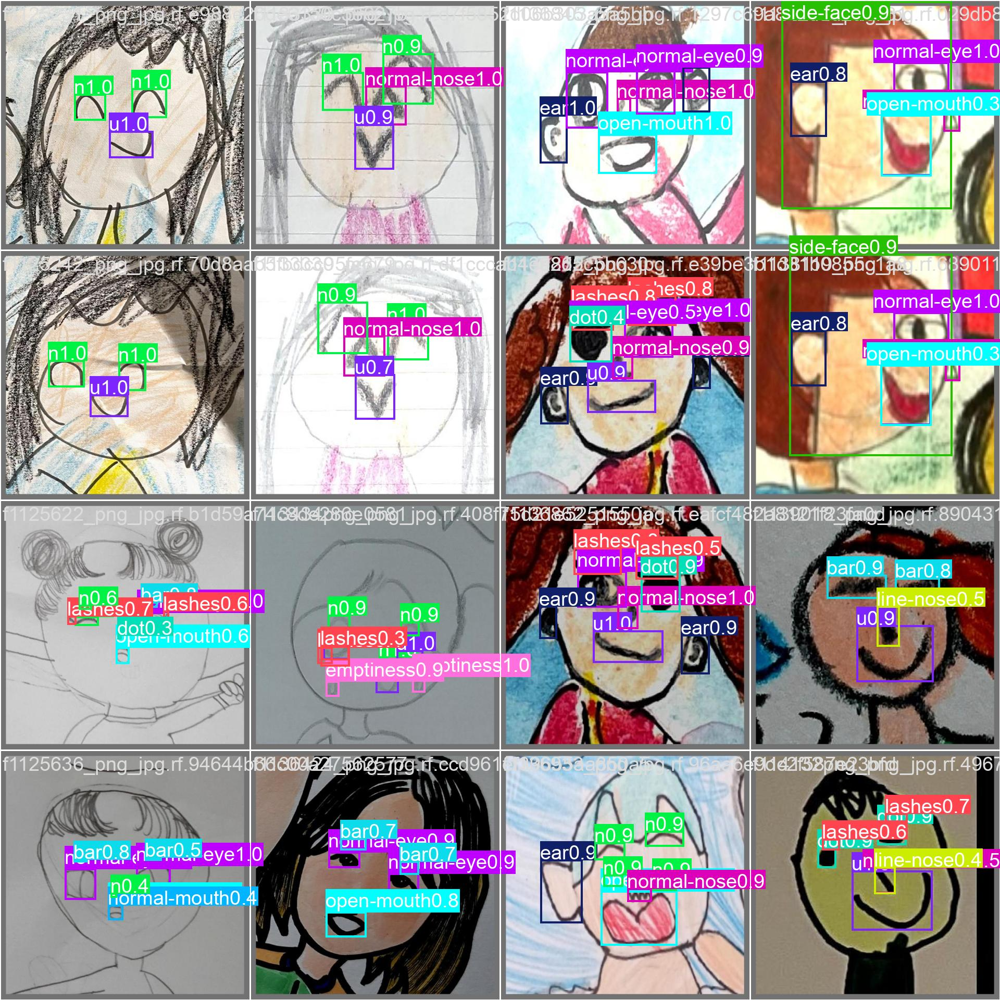





Labels



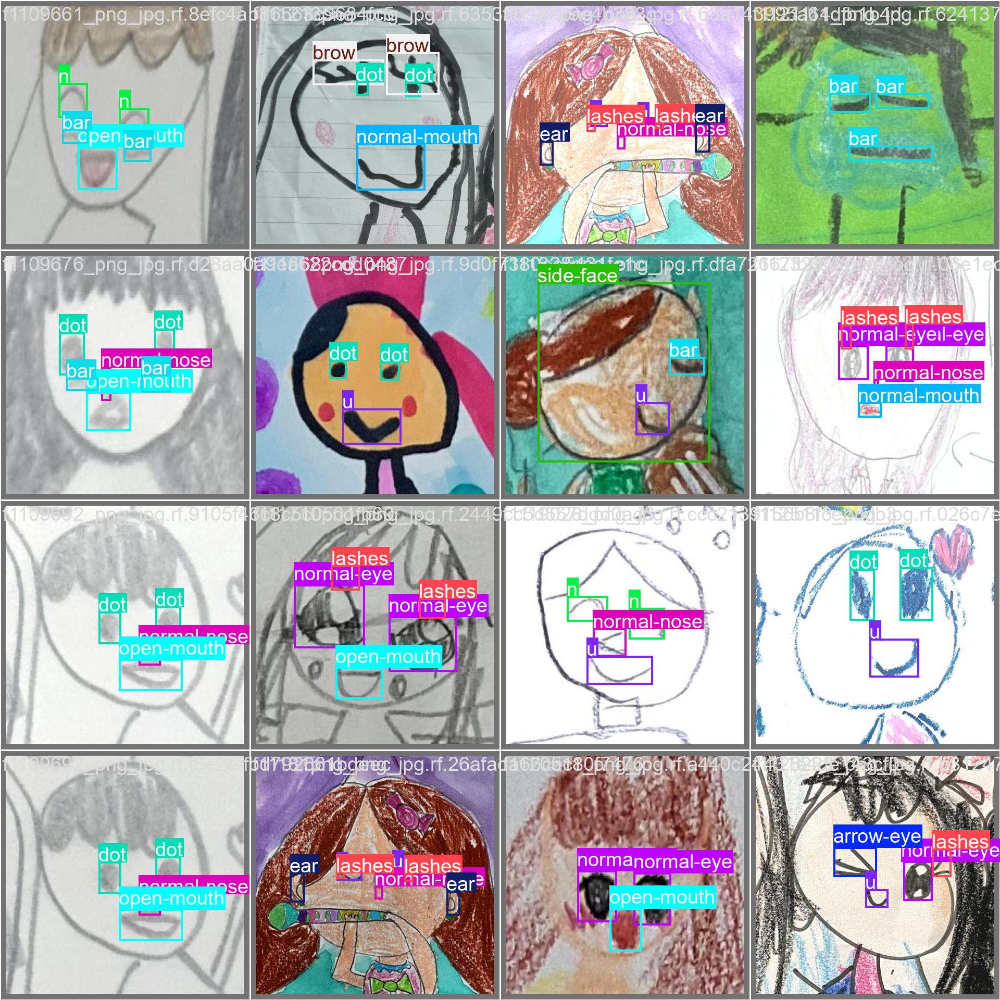





Predictions



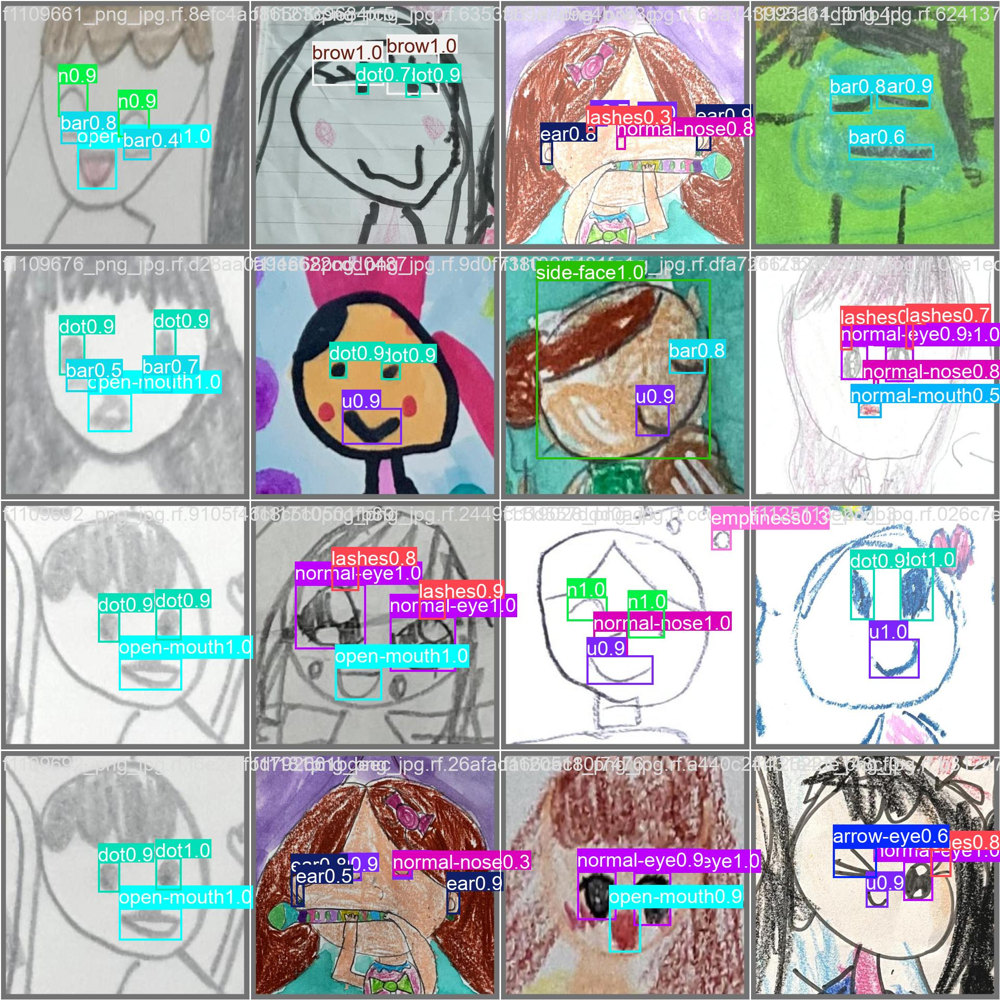





Labels



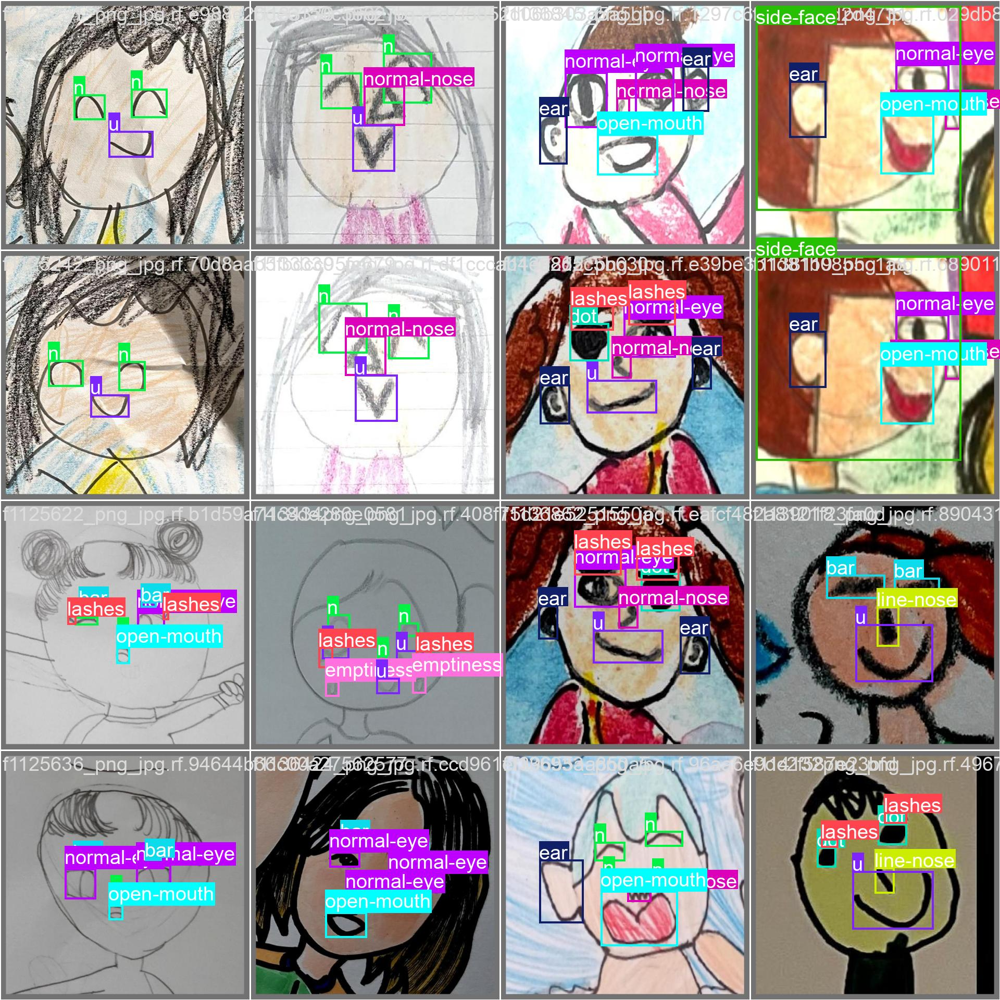





Labels



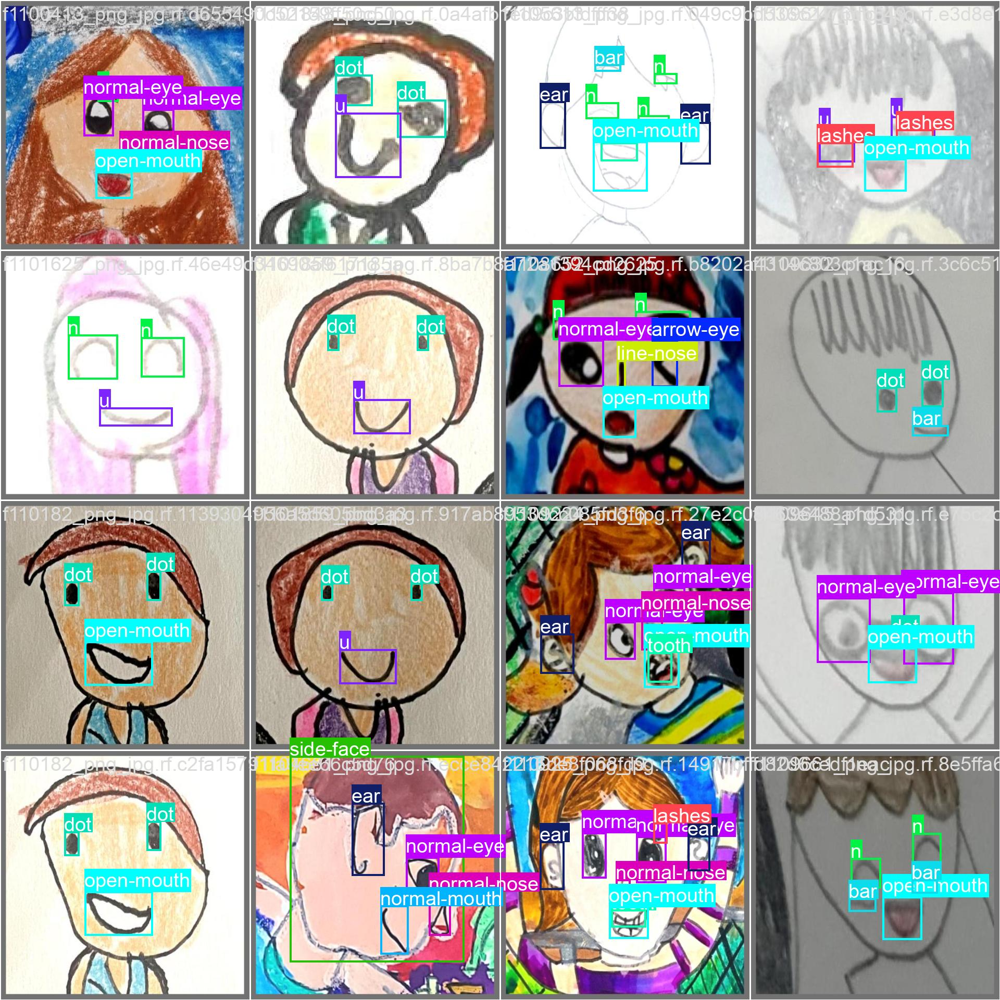

In [ ]:
# display inference on ALL test images
from IPython.display import Image, display

i = 0
limit = 25  # max images to print
for imageName in glob.glob("/content/runs/detect/val/*.jpg"):  # assuming JPG
    if i < limit:
        if "pred" in imageName:
            print("Predictions\n")
        else:
            print("Labels\n")
        display(Image(filename=imageName))
        print("\n\n\n")
    i = i + 1

Самое время разобраться с тем, как лежат правильные ответы в файлах!

Первая циферка -- класс. Дальше 4 координаты бибокса.

Красивая картинка с описанием вот тут: https://roboflow.com/formats/yolov8-pytorch-txt

In [ ]:
!cat {dataset.location}/train/labels/f11001png_png_jpg.rf.78537a466be6235544dd84f33d3c38bb.txt

4 0.79296875 0.54375 0.12265625 0.17265625
9 0.34296875 0.4984375 0.17421875 0.125
8 0.6125 0.48515625 0.1328125 0.09453125
11 0.45390625 0.60625 0.071875 0.06171875
4 0.19921875 0.575 0.11015625 0.1421875
15 0.453125 0.66328125 0.13203125 0.09453125
6 0.3453125 0.40703125 0.121875 0.078125
6 0.6203125 0.42734375 0.1046875 0.05234375

Заодно и на волшебный .yaml глянем:

In [ ]:
!cat {dataset.location}/data.yaml

names:
- arrow-eye
- bar
- brow
- dot
- ear
- emptiness
- lashes
- line-nose
- n
- normal-eye
- normal-mouth
- normal-nose
- open-mouth
- side-face
- tooth
- u
nc: 16
roboflow:
  license: CC BY 4.0
  project: ogo-2
  url: https://universe.roboflow.com/hsedeeplearning/ogo-2/dataset/1
  version: 1
  workspace: hsedeeplearning
test: ../test/images
train: ../train/images
val: ../valid/images


Библиотека на самом деле ещё и вагон полезных кривых строит, давайте посмотрим:

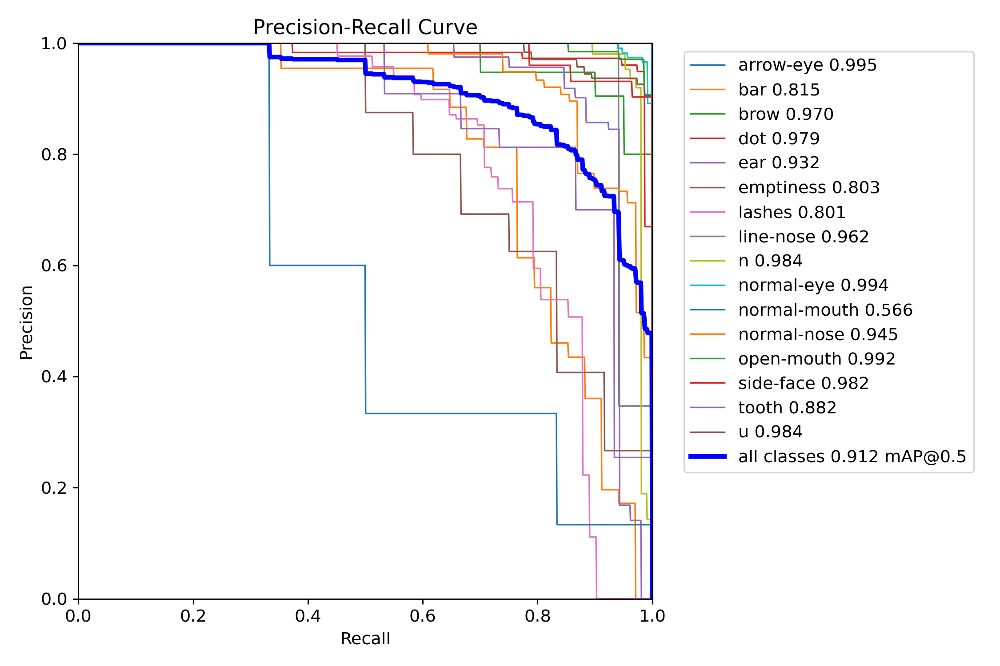

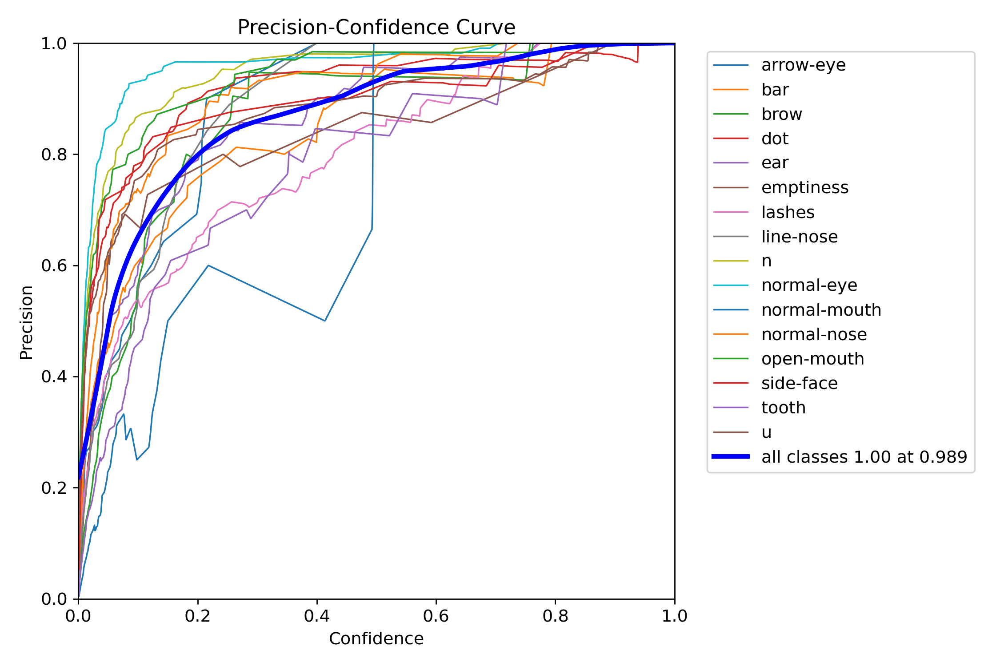

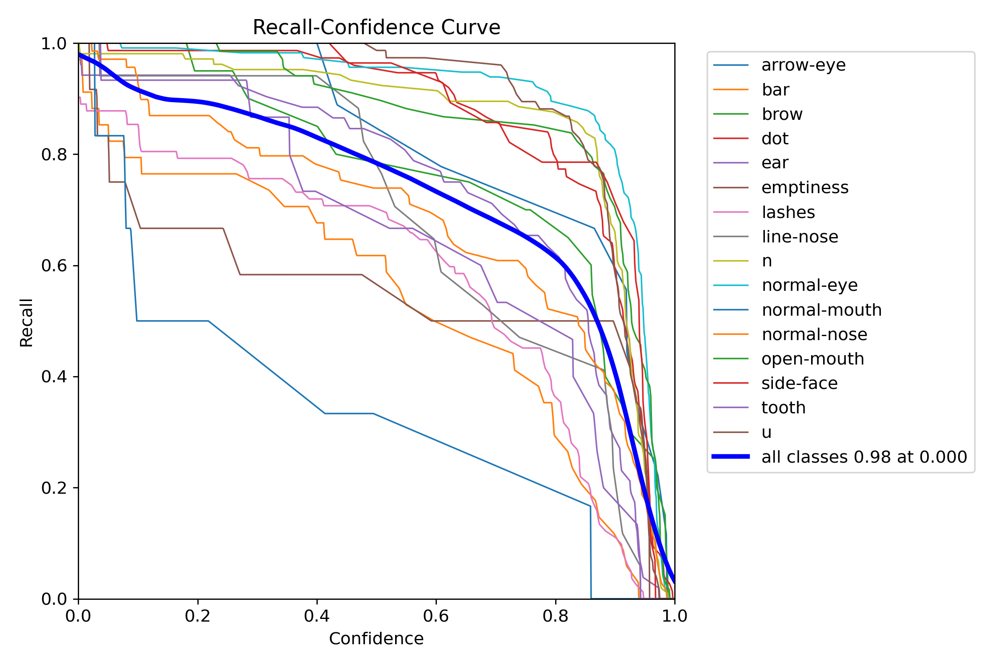

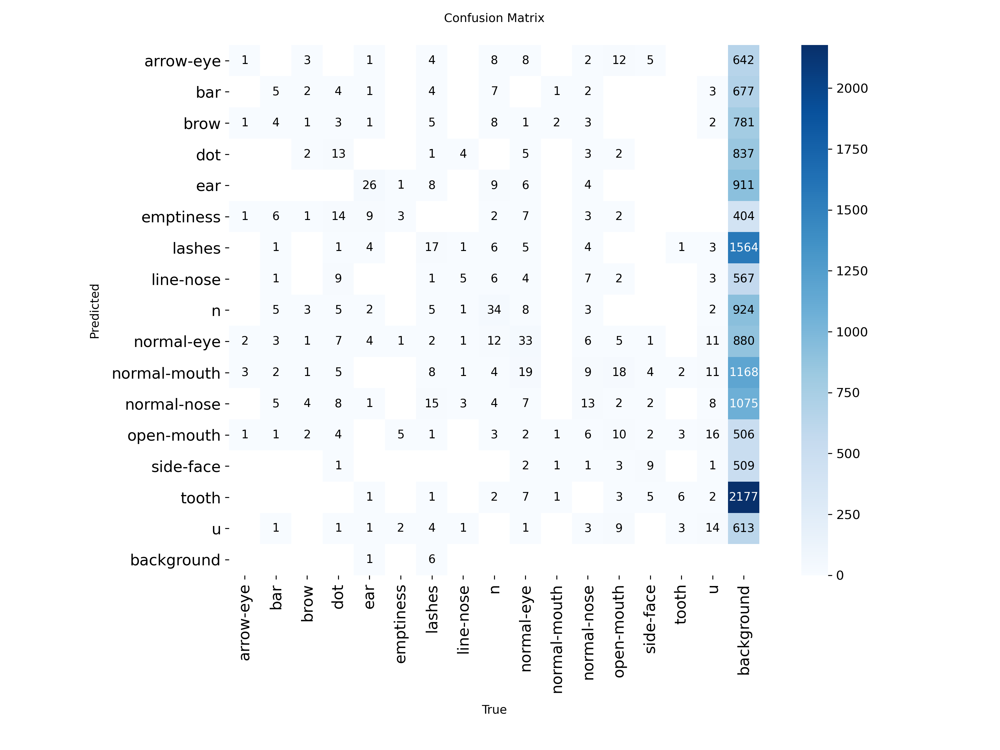

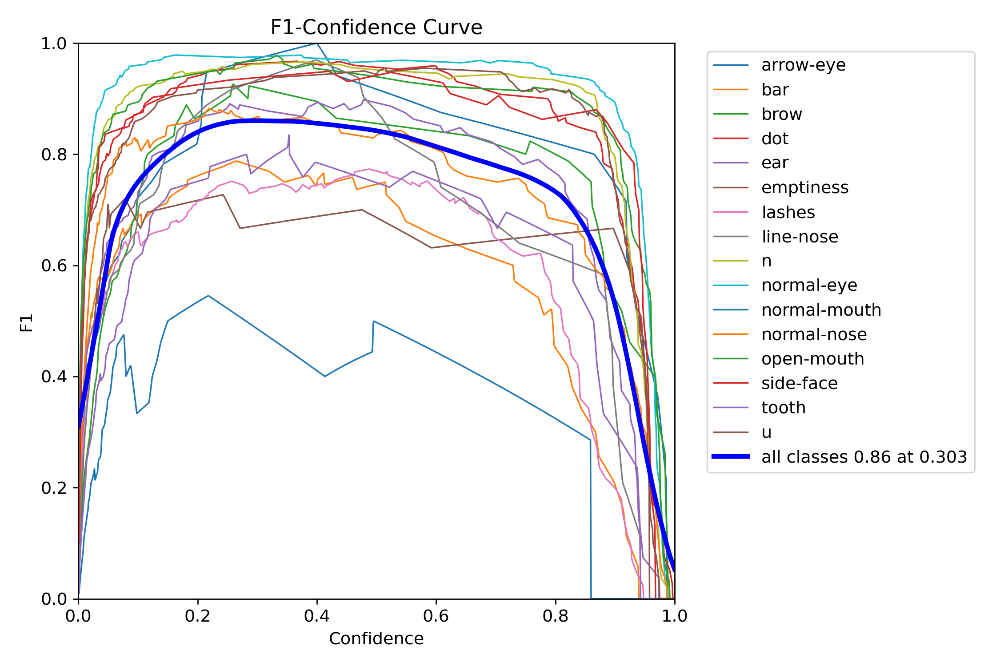

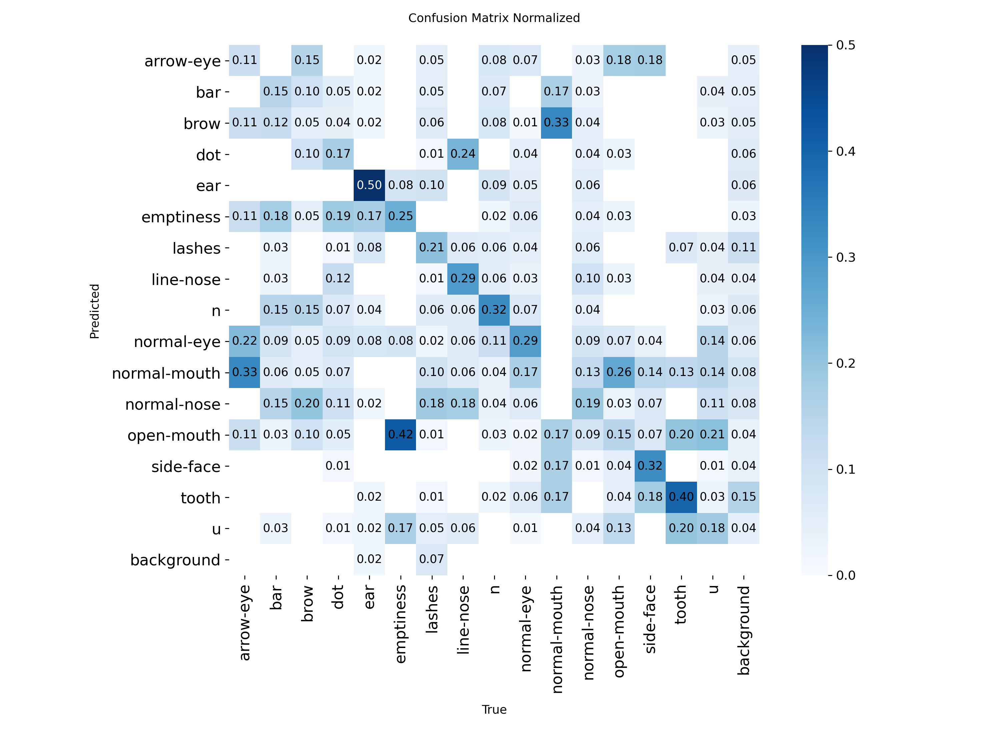

In [ ]:
# display inference on ALL test images
from IPython.display import Image, display

i = 0
limit = 25  # max images to print
for imageName in glob.glob("/content/runs/detect/val/*.png"):  # assuming PNG
    if i < limit:
        display(Image(filename=imageName))
        print("\n\n\n")
    i = i + 1

In [ ]:
!cat /content/runs/detect/train/args.yaml

task: detect
mode: train
model: yolo11n.pt
data: /content/ogo-2-1/data.yaml
epochs: 15
time: null
patience: 100
batch: 16
imgsz: 640
save: true
save_period: -1
cache: false
device: ''
workers: 8
project: null
name: train
exist_ok: false
pretrained: true
cls_remap: true
optimizer: auto
verbose: true
seed: 0
deterministic: true
single_cls: false
rect: false
cos_lr: false
close_mosaic: 10
resume: false
amp: true
fraction: 1.0
profile: false
freeze: null
multi_scale: 0.0
compile: false
channels_last: null
overlap_mask: true
mask_ratio: 4
dropout: 0.0
val: true
split: val
save_json: false
conf: null
iou: 0.7
max_det: 300
quantize: null
dnn: false
plots: true
nms: null
source: null
vid_stride: 1
stream_buffer: false
visualize: false
augment: false
agnostic_nms: false
classes: null
retina_masks: false
embed: null
show: false
save_frames: false
save_txt: false
save_conf: false
save_crop: false
show_labels: true
show_conf: true
show_boxes: true
line_width: null
format: torchscript
optimize: fal